# L3.3 · Fraud classification — which payments should we review?

**Day 3 slides** 14–17 and 20

### The problem

The review team can only look at a small number of card payments per day. How can we put more recorded fraud cases near the top of that list?

### What we’re doing

Make one clue from earlier payments, compare trees and a forest, then see how many fraud cases fit into a 20-review-per-day queue.

### Why we’re doing it

Fraud is rare, so accuracy can be misleading. A review queue makes the goal concrete and helps explain why we focus on ranking and the number of cases caught.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

**What the model guesses.** Fraud or usual payment. It gives each row a score so we can decide which payments reach the review queue.

## Setup · Open the data

Read six columns from the course transaction file. This setup may take a moment. We keep later months for checking and will fit on a small sample of earlier payments. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

columns = ["card_id", "txn_ts", "amount_aed", "distance_from_home_km", "merchant_risk_score", "is_fraud"]
events = pd.read_csv(data / "card_transactions.csv.gz", usecols=columns, parse_dates=["txn_ts"])
events = events.sort_values("txn_ts", kind="stable").reset_index(drop=True)

## 1 · Ask whether the card was just used

**What we’re doing.** Find the time since the previous payment for each card. Turn it into a flag for activity within the previous hour.

**Why.** A sudden run of payments can be a clue. Using an earlier payment means the clue is available when we score this row. A previous payment with the same timestamp does not count toward this flag.

**Look for.** The flag is one if the previous observed payment was strictly earlier and less than an hour ago. A zero includes cards with no earlier payment observed.

In [2]:
elapsed = events.groupby("card_id", sort=False)["txn_ts"].diff()
events["active_in_previous_hour"] = elapsed.between(
    pd.Timedelta(seconds=0), pd.Timedelta(hours=1), inclusive="neither"
).astype(int)
display(events[["txn_ts", "amount_aed", "active_in_previous_hour"]].sample(4, random_state=3))

,txn_ts,amount_aed,active_in_previous_hour
477023,2025-05-28 22:20:55,1478.51,0
203412,2025-04-25 18:18:54,917.82,0
874673,2025-07-16 11:49:29,165.51,0
781387,2025-07-04 21:24:02,161.27,0


## 2 · Keep months in order

**What we’re doing.** Use April–July for learning, August to choose, and September to check. Keep all August and September rows with the selected inputs present.

**Why.** A future test should resemble the mix the team will face. We use a smaller training sample to make fitting quick while keeping the actual rarity in the check months.

**Look for.** Read the small August fraud share. Always saying no would be correct almost all the time and would catch zero fraud.

In [3]:
inputs = ["amount_aed", "distance_from_home_km", "merchant_risk_score", "active_in_previous_hour"]
available = events.dropna(subset=inputs + ["is_fraud"])
earlier = available[available["txn_ts"] < "2025-08-01"]
valid = available[available["txn_ts"].dt.month == 8]
test = available[available["txn_ts"].dt.month == 9]
positive = earlier[earlier["is_fraud"] == 1].sample(n=800, random_state=42)
negative = earlier[earlier["is_fraud"] == 0].sample(n=3200, random_state=42)
train = pd.concat([positive, negative])
print(f"August fraud share among eligible rows: {valid['is_fraud'].mean():.2%}")

August fraud share among eligible rows: 0.19%


## 3 · Read a tree’s first questions

**What we’re doing.** Fit a small tree on the earlier sample and show its questions.

**Why.** A tree can be followed from its first question to the final box. Each final box summarises the recorded answers among its training rows.

**Look for.** Read the top question. Follow the left branch when its condition is true.

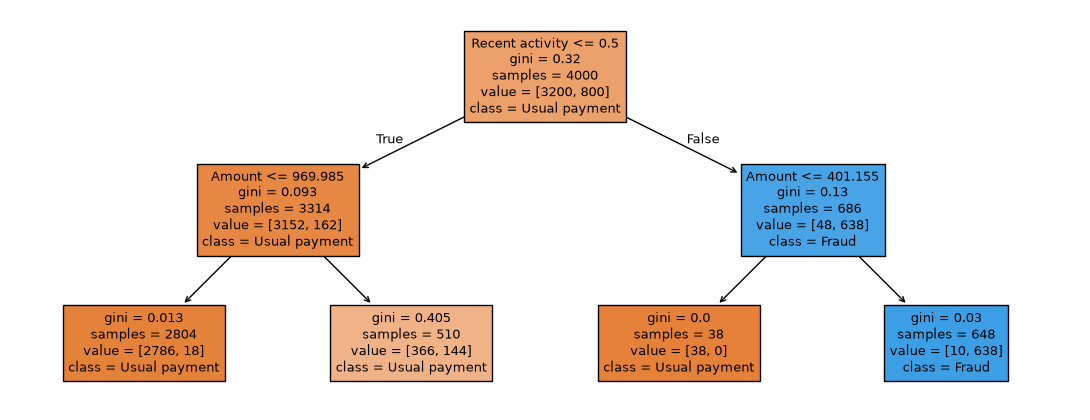

In [4]:
shallow = DecisionTreeClassifier(max_depth=2, min_samples_leaf=30, random_state=42)
shallow.fit(train[inputs], train["is_fraud"])
fig, ax = plt.subplots(figsize=(11, 4.3))
plot_tree(shallow, feature_names=["Amount", "Distance", "Merchant risk", "Recent activity"],
          class_names=["Usual payment", "Fraud"], filled=True, fontsize=9, ax=ax)
plt.tight_layout()
plt.show()

## 4 · Give the tree several ways to stop

**What we’re doing.** Compare one small tree, one larger tree, and one that can remove small branches with pruning.

**Why.** A deep tree can fit more details from the learning examples. Limits on depth, leaves and minimum group size can help. Pruning removes branches that contribute too little to the training objective.

**Look for.** Compare numbers of leaves and average precision on August. A larger tree is only useful when its scores improve on new rows.

In [5]:
larger = DecisionTreeClassifier(max_depth=8, min_samples_leaf=12, max_leaf_nodes=40, random_state=42)
pruned = DecisionTreeClassifier(max_depth=8, min_samples_leaf=12, max_leaf_nodes=40,
                                ccp_alpha=.001, random_state=42)
trees = {"Small tree": shallow, "Larger tree": larger, "Pruned tree": pruned}
for name, tree in trees.items():
    tree.fit(train[inputs], train["is_fraud"])
    scores = tree.predict_proba(valid[inputs])[:, 1]
    print(name, "· leaves:", tree.get_n_leaves(),
          "· August average precision:", round(average_precision_score(valid["is_fraud"], scores), 3))

Small tree · leaves: 4 · August average precision: 0.226
Larger tree · leaves: 25 · August average precision: 0.565
Pruned tree · leaves: 8 · August average precision: 0.244


## 5 · Compare a forest and boosting

**What we’re doing.** Fit a random forest and a small boosting model on the same learning rows.

**Why.** A forest averages many trees trained on different samples. Each split can use a random subset of clues. Boosting builds trees in sequence so each new tree works on previous mistakes.

**Look for.** Average precision helps compare the order of the scores. Because we changed the training class mix, use these scores for ranking in this example.

In [6]:
forest = RandomForestClassifier(n_estimators=24, max_depth=7, min_samples_leaf=15, random_state=42)
boosting = HistGradientBoostingClassifier(max_iter=30, max_leaf_nodes=8, random_state=42)
for name, model in [("Forest", forest), ("Boosting", boosting)]:
    model.fit(train[inputs], train["is_fraud"])
    score = model.predict_proba(valid[inputs])[:, 1]
    print(name, "· August average precision:", round(average_precision_score(valid["is_fraud"], score), 3))

Forest · August average precision: 0.685


Boosting · August average precision: 0.637


**One forest term from the trainer guide.** Each tree learns from rows
drawn with replacement, so a row can appear several times and some rows
are left out. Out-of-bag evaluation uses trees that left a row out to
check that row. This notebook compares models on the later August rows,
which match the timing of the review exercise.

## 6 · See which clues the forest uses

**What we’re doing.** Compare the forest’s record of its training splits with a check that shuffles one clue on August rows.

**Why.** If shuffling a clue makes the scores less useful, the model was relying on it. Training split counts can favour clues with many possible values. Clues with similar information can share importance.

**Look for.** Read both columns as comparisons within their own units. These are checks on a model’s behaviour. They do not tell us what causes fraud.

In [7]:
review = valid.sample(n=10000, random_state=42)
shuffled = permutation_importance(forest, review[inputs], review["is_fraud"],
                                  scoring="average_precision", n_repeats=3, random_state=42)
importance = pd.DataFrame({"Clue": inputs, "Split importance": forest.feature_importances_,
                           "Score drop after shuffle": shuffled.importances_mean})
display(importance.round(3))

,Clue,Split importance,Score drop after shuffle
0,amount_aed,0.241,0.336
1,distance_from_home_km,0.178,0.429
2,merchant_risk_score,0.164,0.316
3,active_in_previous_hour,0.417,0.321


## 7 · Use the same daily budget for each model

**What we’re doing.** Put the highest-scored 20 payments per day into a pretend queue. Use August to choose a model and report what it catches in September.

**Why.** The team’s time is limited. Comparing the same number of reviews per day matches the question we started with.

**Look for.** Recall at this budget divides the caught cases by all eligible fraud cases from that month. The scored rows remain at the natural class mix.

In [8]:
def daily_queue(rows, model):
    queue = rows[["txn_ts", "is_fraud"]].copy()
    queue["score"] = model.predict_proba(rows[inputs])[:, 1]
    queue["day"] = queue["txn_ts"].dt.date
    return queue.sort_values("score", ascending=False).groupby("day", sort=False).head(20)

options = {**trees, "Forest": forest, "Boosting": boosting}
caught = {name: daily_queue(valid, model)["is_fraud"].sum() for name, model in options.items()}
display(pd.Series(caught, name="August cases caught").sort_values(ascending=False))
chosen = max(caught, key=caught.get)
queue = daily_queue(test, options[chosen])
print(f"September · {chosen} · {len(queue)} reviews · caught {queue['is_fraud'].sum()} of {test['is_fraud'].sum()}")

Boosting       272
Larger tree    266
Forest         260
Small tree     157
Pruned tree    148
Name: August cases caught, dtype: int64

September · Boosting · 600 reviews · caught 200 of 264


### Your turn

Why do we compare methods using 20 reviews per day? What would happen to the team’s work and the number of cases caught if the budget rose to 40?